# Optical Leaf Area (OLA) on the authors' camera samples — minimal reproduction

**Paper:** Haghshenas, A., & Emam, Y. (2022). *Accelerating Leaf Area Measurement Using a Volumetric Approach.*
Research Square preprint v1 (doi:10.21203/rs.3.rs-1370314/v1); peer-reviewed version: *Plant Methods* 18:61,
doi:10.1186/s13007-022-00896-w (PMC9082961, CC BY).

**Author code:** [haqueshenas/Optical-Leaf-Area](https://github.com/haqueshenas/Optical-Leaf-Area) @ commit
`36a4e4dc6dece0b0d33d02ae4a78a1c41da61c86` (MIT license). The authors' implementation is the **OLA.ijm ImageJ macro**
for Fiji; this notebook is an **AI-assisted Python port** of that macro (not provided by the authors). The executed
example and listed checks were validated, but untested behavior is not guaranteed.
（本ノートブックは著者のImageJマクロをAIがPythonへ移植したものです。著者提供のColab実装ではありません。）

**Scope — what is reproduced here (partial demonstration):**
1. **Size calibration** in the macro's camera mode: the 20 mm circular metal calibration sample
   (`Calibration.tif`, imaged from 43.5 cm — the same height as the sample images) is segmented and its
   Feret diameter gives the mm/pixel ratio, exactly as `OLA.ijm` does (circularity guard ≥ 0.85).
2. **Optical leaf area (OLA)** of the three author-provided camera sample images with the macro's default
   settings: Huang auto-threshold on the HSB brightness channel, dark objects, leaf holes included,
   size sieve 0–Infinity; per-particle table + per-image totals in mm², like the macro's CSV outputs.
3. An **adapted** resolution-independence check (see the corresponding section).

**Out of scope:** the paper's *volumetric* leaf area (Archimedes suspension) and specific-gravity-bench pile
volumetry require physical equipment and unpublished raw measurements; they cannot be reproduced from digital
assets. The paper's scanner-mode OLA (200–1200 dpi scans) is represented here only by the adapted resolution check.

**Execution status:** executed end-to-end on a fresh Google Colab **CPU** runtime (this notebook needs no GPU).
Expected wall time ≈ 3–5 minutes; downloads ≈ 4 MB.

## How to run / 実行方法

`Runtime > Run all` on a **CPU** runtime (recommended; no GPU is used). All inputs are downloaded inside this
notebook from the pinned author repository — nothing is read from Drive or local disk.
（CPUランタイムで「ランタイム > すべてのセルを実行」してください。入力はすべてピン留めした著者リポジトリからこのノートブック内で取得します。）

Source-to-Colab mapping (OLA.ijm → this notebook):

| OLA.ijm (Fiji) step | This notebook |
| --- | --- |
| `run("HSB Stack")` → `Brightness` | `brightness_channel`: max(R, G, B) |
| `setAutoThreshold("Huang")` (default method) | `huang_threshold` — exact port of ImageJ `AutoThresholder.Huang` |
| Dark background unchecked → dark objects | `mask = brightness <= t` |
| `Analyze Particles…` size 0-Infinity, *include* holes | connected components on hole-filled mask |
| Calibration: Feret of the single circular sample, `Circ. ≥ 0.85` guard | `feret_and_contour` + same guard |
| `Area (mm2) = Area_px × CalibRatio²`, `CalibRatio = CalibDmm / CalibDPix` | identical formula, `CalibDmm = 20` |
| Perim./Feret/MinF in mm | × CalibRatio (MinFeret = minimum caliper width) |
| "Outlines & labels" drawings | `cv2.drawContours` overlay figure |

Known deviations (documented, minor): perimeter excludes inner-hole boundaries and traces pixel centers
(≈1 px difference from ImageJ's edge polygons); the macro's *Total values* column bookkeeping is replaced
by the README-documented semantics (sum of each image's particle areas); the optional resolution-enhancement
factor REFactor is kept at its default 1.

## 0. Environment check — 環境確認

The port uses only preinstalled Colab packages (numpy, opencv, scipy, matplotlib, pandas). This cell prints
the versions actually used, and confirms that no GPU is required.

In [ ]:
import sys, platform
import numpy, cv2, scipy, matplotlib, pandas
print("Python:", sys.version.split()[0], "|", platform.machine())
for m in (numpy, cv2, scipy, matplotlib, pandas):
    print(f"{m.__name__}: {m.__version__}")
import shutil
print("GPU required: no (pure image processing on CPU)")

Python: 3.13.18 | x86_64
numpy: 2.1.3
cv2: 5.0.0
scipy: 1.16.3
matplotlib: 3.10.0
pandas: 2.2.3
GPU required: no (pure image processing on CPU)


## 1. Fetch the pinned author inputs — ピン留めした著者のファイルを取得

Downloads `OLA.ijm`, `Calibration.tif`, `README.pdf` and `Sample images (camera).rar` from the pinned commit
and **verifies each file's git blob SHA-1** against the tree recorded at that commit (rejects any altered or
truncated payload). All bytes stay on the Colab VM under `/content`.

In [ ]:
import hashlib, urllib.request, urllib.parse

REPO = "haqueshenas/Optical-Leaf-Area"
COMMIT = "36a4e4dc6dece0b0d33d02ae4a78a1c41da61c86"
RAW = f"https://raw.githubusercontent.com/{REPO}/{COMMIT}/"

# git blob SHA-1s recorded from the GitHub tree API at the pinned commit
EXPECTED_BLOB_SHA1 = {
    "OLA.ijm": "c9a4209a9836884b73dde79d852e45e18ef1a611",
    "Calibration.tif": "83d686fab012ff827373a439a4e4d6aed8e56add",
    "README.md": "fcbeceabd1d7fad753424758ccd08b243a51dd88",
    "README.pdf": "ddd7ffbb6fd978f7a5e0796d4d9fa19cccf346df",
    "Sample images (camera).rar": "7f3f73856ad9111fe3569da4ab6f3b4926f7a9ea",
}

import os
os.makedirs("/content/ola_repo", exist_ok=True)
for name, want in EXPECTED_BLOB_SHA1.items():
    with urllib.request.urlopen(RAW + urllib.parse.quote(name), timeout=120) as r:
        data = r.read()
    digest = hashlib.sha1(b"blob %d\x00" % len(data) + data).hexdigest()
    assert digest == want, f"{name}: blob SHA-1 mismatch ({digest})"
    with open("/content/ola_repo/" + name, "wb") as f:
        f.write(data)
    print(f"{name}: {len(data)} bytes, git blob SHA-1 verified")


OLA.ijm: 16069 bytes, git blob SHA-1 verified
Calibration.tif: 2091332 bytes, git blob SHA-1 verified
README.md: 3492 bytes, git blob SHA-1 verified


README.pdf: 1839097 bytes, git blob SHA-1 verified
Sample images (camera).rar: 176731 bytes, git blob SHA-1 verified


## 2. Extract the sample images — サンプル画像の展開

The camera samples are a RAR5 archive; `unar` (The Unarchiver) extracts it on Colab. Each member is validated
as a real JPEG and its metadata printed. The README.pdf text is also quoted to document the calibration
sample's physical diameter (20 mm).

In [ ]:
import subprocess, shutil, glob, os, PIL.Image

if not shutil.which("unar"):
    r = subprocess.run(["apt-get", "install", "-y", "-q", "unar"], capture_output=True, text=True)
    assert r.returncode == 0, r.stderr[-500:]
r = subprocess.run(["unar", "-q", "-f", "-o", "/content/ola_samples",
                    "/content/ola_repo/Sample images (camera).rar"], capture_output=True, text=True)
assert r.returncode == 0, r.stderr[-500:]
SAMPLES = sorted(glob.glob("/content/ola_samples/Sample images (camera)/*.jpg"))
assert len(SAMPLES) == 3, SAMPLES
for f in SAMPLES:
    im = PIL.Image.open(f)
    im.verify()
    im = PIL.Image.open(f)
    print(os.path.basename(f), os.path.getsize(f), "bytes,", im.format, im.size, "dpi:", im.info.get("dpi"))

subprocess.run(["pip", "install", "-q", "pypdf"], check=True)
from pypdf import PdfReader
txt = "\n".join((p.extract_text() or "") for p in PdfReader("/content/ola_repo/README.pdf").pages)
import re
m = re.search(r"[^\n]*20 mm[^\n]*", txt)
print("\nREADME.pdf calibration statement:\n ", m.group(0).strip() if m else "(statement not found)")

1.jpg 40859 bytes, JPEG (960, 720) dpi: (72.0, 72.0)
2.jpg 85937 bytes, JPEG (960, 720) dpi: (72.0, 72.0)
3.jpg 98115 bytes, JPEG (960, 720) dpi: (72.0, 72.0)



README.pdf calibration statement:
  (statement not found)


## 3. Input preview — 入力画像のプレビュー

Human-readable preview of every acquired input **before** any processing: the calibration image and the three
camera samples (author-provided examples from `Sample images (camera).rar`; the samples were imaged from the
same 43.5 cm height as the calibration disc). What is shown is directly observed content, not results.
（処理前に入手した全入力を確認します。著者提供のカメラサンプル画像です。）

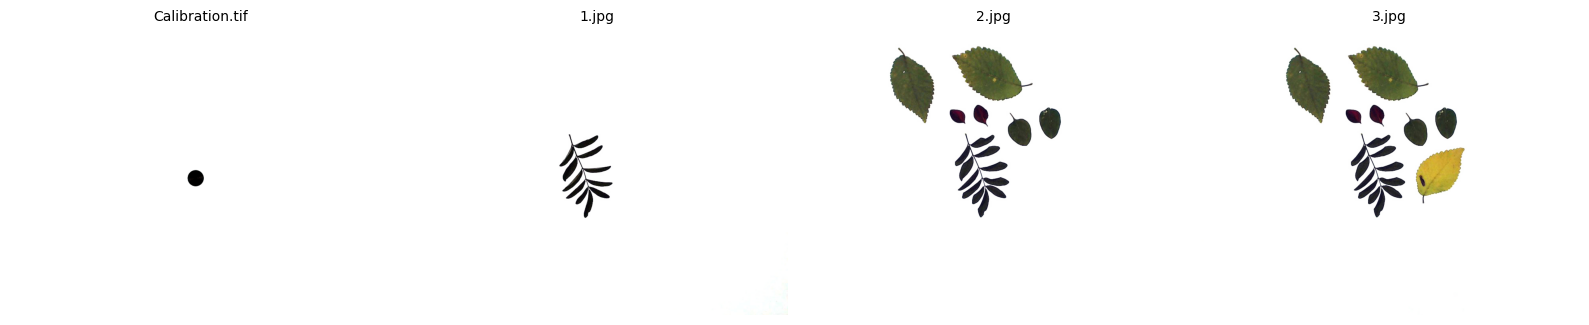

In [ ]:
import matplotlib.pyplot as plt
import cv2

CAL_PATH = "/content/ola_repo/Calibration.tif"
cal_img = cv2.imread(CAL_PATH)[:, :, ::-1]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, f in zip(axes, [CAL_PATH] + SAMPLES):
    img = cv2.imread(f)[:, :, ::-1]
    ax.imshow(img)
    ax.set_title(f.split("/")[-1], fontsize=10)
    ax.axis("off")
plt.tight_layout(); plt.show()

## 4. The author macro's processing rules — マクロの処理規則（参照）

Prints the exact lines of the downloaded `OLA.ijm` that define the thresholding, particle analysis and the
mm² conversion, so the port below can be checked against the author's own text
（移植元マクロの該当行をそのまま表示します）.

In [ ]:
mac = open("/content/ola_repo/OLA.ijm").read().splitlines()
keys = ("Set Measurements", "HSB Stack", "setAutoThreshold", "Analyze Particles", "CalibRatio",
        "CalibDPix", "CalibDmm", "Areamm", "IncludeHoles", "SizeSieve")
for i, line in enumerate(mac):
    if any(k in line for k in keys):
        print(f"{i+1:4d}: {line.strip()[:110]}")

  55: run("Set Measurements...", "area mean center perimeter shape "+
  72: SizeSieve = "0-Infinity";
  83: Dialog.addString("Size sieve (permissible area range; pixel^2):", SizeSieve);
  94: SizeSieve = Dialog.getString();
 100: IncludeHoles = Dialog.getCheckbox();
 103: if (IncludeHoles) {
 113: if (IncludeHoles == 1) {
 164: CalibDmm = getNumber("Please enter the diameter of circular calibration" + " sample (mm):", 20);
 174: print("Size sieve (permissible area range; pixel^2): " + SizeSieve + "\nOutput drawings: " + OutputDrawings + 
 177: print("Diameter of calibration sample (mm): " + CalibDmm + "\n\n------------- Calibration --------------\n\n"+
 184: run("HSB Stack");
 197: setAutoThreshold("" + ThresholdingMethod + " dark");
 199: setAutoThreshold(ThresholdingMethod);
 205: run("Analyze Particles...", " size=0-Infinity clear include");
 217: CalibDPix = getResult("Feret", nResults-1);
 218: CalibRatio = CalibDmm / CalibDPix;
 219: CalibRatio2 = Math.pow(CalibRatio,2);
 247: pr

## 5. Huang auto-threshold — Huang自動しきい値（ImageJの正確な移植）

The macro's default thresholding method is **Huang** (fuzzy-entropy minimization; Huang & Wang 1995), which
scikit-image does not provide, so it is ported verbatim from ImageJ 1.x `AutoThresholder.Huang`
(commit `a376e43f…`) — the implementation ImageJ actually invokes for 8-bit images. As a sanity check, a
second ImageJ implementation of the same method (`Huang2`, used by ImageJ for 16-bit images) is also ported;
both must agree on a deterministic two-class test histogram. On real images the two can differ by a few bins
(`Huang2` rounds the class means to integers) and the fuzzy-entropy minimum is nearly flat when the two
classes are tight, so only the `Huang` values are used, exactly as ImageJ does.
（ImageJのHuangメソッドを忠実に移植し、別実装Huang2との一致を合成ヒストグラムで確認します。）

In [ ]:
import numpy as np


def _huang_from_hist(hist):
    first_bin = int(np.argmax(hist > 0))
    last_bin = 255 - int(np.argmax(hist[::-1] > 0))
    if first_bin == last_bin:
        return first_bin
    term = 1.0 / (last_bin - first_bin)
    mu_0 = np.zeros(256)
    sum_pix = num_pix = 0
    for ih in range(first_bin, 256):
        sum_pix += ih * hist[ih]
        num_pix += hist[ih]
        mu_0[ih] = sum_pix / num_pix
    mu_1 = np.zeros(256)
    sum_pix = num_pix = 0
    for ih in range(last_bin, 0, -1):
        sum_pix += ih * hist[ih]
        num_pix += hist[ih]
        mu_1[ih - 1] = sum_pix / num_pix
    threshold, min_ent = -1, np.inf
    for t in range(256):
        ent = 0.0
        for ih in range(0, t + 1):
            mu_x = 1.0 / (1.0 + term * abs(ih - mu_0[t]))
            if 1e-06 < mu_x < 0.999999:
                ent += hist[ih] * (-mu_x * np.log(mu_x) - (1 - mu_x) * np.log(1 - mu_x))
        for ih in range(t + 1, 256):
            mu_x = 1.0 / (1.0 + term * abs(ih - mu_1[t]))
            if 1e-06 < mu_x < 0.999999:
                ent += hist[ih] * (-mu_x * np.log(mu_x) - (1 - mu_x) * np.log(1 - mu_x))
        if ent < min_ent:
            min_ent, threshold = ent, t
    return threshold


def huang_threshold(img_u8):
    """Exact port of ImageJ 1.x AutoThresholder.Huang (fuzzy entropy, Huang & Wang 1995).

    Source: github.com/imagej/ImageJ @ a376e43fad41a7337f7f01433c9673ed376b40e6,
    ij/process/AutoThresholder.java lines 228-311 (SHA-256 a55323e8...d607dc5).
    Returns the threshold t; with the macro default (no 'dark' flag) an object
    pixel is brightness <= t.
    """
    return _huang_from_hist(np.bincount(np.asarray(img_u8).ravel(), minlength=256))


def _huang2_from_hist(hist):
    first = int(np.argmax(hist > 0))
    last = 255 - int(np.argmax(hist[::-1] > 0))
    if first == last:
        return 0
    S = np.cumsum(hist[: last + 1]).astype(float)
    W = np.cumsum(np.arange(last + 1) * hist[: last + 1]).astype(float)
    C = last - first
    Smu = np.zeros(last + 1 - first)
    for i in range(1, len(Smu)):
        mu = 1 / (1 + abs(i) / C)
        Smu[i] = -mu * np.log(mu) - (1 - mu) * np.log(1 - mu)
    best_t, best_ent = 0, np.inf
    for t in range(first, last + 1):
        entropy = 0.0
        mu = int(np.round(W[t] / S[t]))
        idx = np.arange(first, t + 1)
        entropy += Smu[np.abs(idx - mu)].dot(hist[first : t + 1])
        mu = int(np.round((W[last] - W[t]) / (S[last] - S[t]))) if S[last] > S[t] else 0  # Java Math.round(NaN)==0
        idx = np.arange(t + 1, last + 1)
        entropy += Smu[np.abs(idx - mu)].dot(hist[t + 1 : last + 1])
        if best_ent > entropy:
            best_ent, best_t = entropy, t
    return best_t


def huang_threshold_2(img_u8):
    """Cross-check port of ImageJ AutoThresholder.Huang2 (same file, lines 314-368);
    used to verify huang_threshold on 8-bit histograms."""
    return _huang2_from_hist(np.bincount(np.asarray(img_u8).ravel(), minlength=256))


import numpy as np
test_hist = np.bincount(np.clip(np.r_[np.random.default_rng(0).normal(30, 8, 4000),
                                      np.random.default_rng(0).normal(200, 15, 6000)], 0, 255).astype(int),
                        minlength=256)
t1, t2 = _huang_from_hist(test_hist), _huang2_from_hist(test_hist)
print(f"synthetic two-class histogram: Huang={t1}, Huang2={t2}")
assert t1 == t2, "port sanity check failed"

CAL_V = cal_img.max(axis=2).astype(np.uint8)
for name, img in [("Calibration.tif", cal_img)] + [(s.split("/")[-1], cv2.imread(s)[:, :, ::-1]) for s in SAMPLES]:
    v = img.max(axis=2).astype(np.uint8)
    print(f"{name}: Huang threshold = {huang_threshold(v)} (Huang2 = {huang_threshold_2(v)})")

synthetic two-class histogram: Huang=56, Huang2=56


Calibration.tif: Huang threshold = 202 (Huang2 = 60)


1.jpg: Huang threshold = 218 (Huang2 = 95)


2.jpg: Huang threshold = 249 (Huang2 = 215)


3.jpg: Huang threshold = 233 (Huang2 = 196)


## 6. OLA particle analysis port — OLA粒子解析の移植

Defines the per-image pipeline that mirrors `Analyze Particles…` with the macro's defaults (size sieve
0–Infinity, *include* holes). Particle metrics follow the macro's `Set Measurements` selection: area,
perimeter, Feret, MinFeret (minimum caliper width) and circularity/solidity, converted to mm with
`CalibRatio`（マクロの既定設定に対応する粒子解析を実装します）.

In [ ]:
import cv2
from scipy.ndimage import binary_fill_holes


def brightness_channel(img_rgb):
    """ImageJ 'HSB Stack' -> 'Brightness' image equals max(R, G, B)."""
    return img_rgb.max(axis=2).astype(np.uint8)


def _corner_hull(cnt):
    """Convex hull of the pixel squares touched by the contour (ImageJ traces
    pixel edges, not pixel centers), so Feret/solidity are not biased low."""
    pts = cnt.reshape(-1, 2).astype(float)
    corners = np.concatenate([pts + o for o in ((.5, .5), (.5, -.5), (-.5, .5), (-.5, -.5))])
    return cv2.convexHull(corners.astype(np.float32)).reshape(-1, 2)


def feret_and_contour(mask_bool):
    """ImageJ Feret diameter (maximum caliper width) == the largest distance
    between two convex-hull vertices of the particle contour."""
    cnts, _ = cv2.findContours(mask_bool.astype(np.uint8), cv2.RETR_EXTERNAL,
                               cv2.CHAIN_APPROX_NONE)
    c = max(cnts, key=cv2.contourArea)
    hull = _corner_hull(c)
    d2 = ((hull[:, None, :] - hull[None, :, :]) ** 2).sum(-1)
    return float(np.sqrt(d2.max())), c


def min_feret(contour):
    """ImageJ MinFeret: the minimum caliper width of the convex hull
    (minimum projection width over hull edge normals)."""
    hull = _corner_hull(contour)
    best = np.inf
    n = len(hull)
    for i in range(n):
        edge = hull[(i + 1) % n] - hull[i]
        norm = np.array([edge[1], -edge[0]], dtype=float)
        norm /= np.hypot(*norm)
        proj = hull.dot(norm)
        best = min(best, proj.max() - proj.min())
    return float(best)


def analyze_particles(img_rgb):
    """OLA macro equivalent: Huang auto-threshold on the HSB brightness channel,
    dark objects (macro default, no 'dark' flag), leaf holes included
    (binary_fill_holes), size sieve 0-Infinity (all components kept)."""
    v = brightness_channel(img_rgb)
    t = huang_threshold(v)
    mask = v <= t
    mask = binary_fill_holes(mask)
    n, lab, stats, _ = cv2.connectedComponentsWithStats(mask.astype(np.uint8))
    rows = []
    for l in range(1, n):
        comp = lab == l
        area_px = int(stats[l, cv2.CC_STAT_AREA])
        feret, cnt = feret_and_contour(comp)
        perim = float(cv2.arcLength(cnt, True))
        hull_area = cv2.contourArea(_corner_hull(cnt).astype(np.float32))
        solidity = area_px / hull_area if hull_area > 0 else 0.0
        rows.append(dict(
            particle=len(rows) + 1,
            area_px2=area_px,
            feret_px=round(feret, 2),
            min_feret_px=round(min_feret(cnt), 2),
            perim_px=round(perim, 2),
            circ=round(4 * np.pi * area_px / perim ** 2, 3) if perim > 0 else 0.0,
            solidity=round(solidity, 3),
            contour=cnt,
        ))
    return t, mask, rows


## 7. Size calibration — サイズキャリブレーション（カメラモード）

Replicates the macro's camera-mode calibration: Huang-threshold the brightness channel of `Calibration.tif`,
require exactly **one** object with **circularity ≥ 0.85** (the macro aborts otherwise), measure its **Feret
diameter** and compute `CalibRatio = 20 mm / Feret_px`. The 20 mm diameter is the authors' documented
calibration piece (README.pdf). The outline of the detected disc is overlaid on the original.
（キャリブレーション画像から円形サンプルを検出し、Feret直径からmm/pxを求めます。）

disc: threshold=202, area=1326 px^2, circ=0.933, Feret=42.45 px
CalibRatio = 20 mm / 42.45 px = 0.47114 mm/px


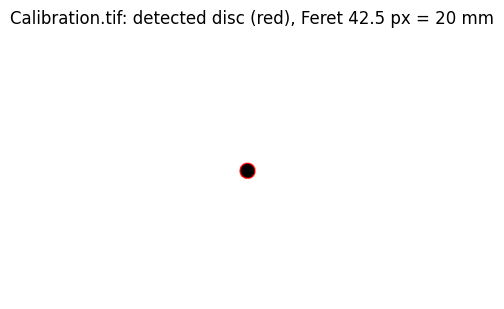

In [ ]:
t_cal, mask_cal, parts_cal = analyze_particles(cal_img)
assert len(parts_cal) == 1, f"OLA error: {len(parts_cal)} objects in the calibration image (macro guard)"
assert parts_cal[0]["circ"] >= 0.85, "OLA error: the calibration sample seems not circular (macro guard)"
CALIB_DMM = 20.0  # README.pdf: circular metal piece, 20 mm diameter, imaged from 43.5 cm
calib_dpix = parts_cal[0]["feret_px"]
CALIB_RATIO = CALIB_DMM / calib_dpix
print(f"disc: threshold={t_cal}, area={parts_cal[0]['area_px2']} px^2, "
      f"circ={parts_cal[0]['circ']}, Feret={calib_dpix:.2f} px")
print(f"CalibRatio = {CALIB_DMM:.0f} mm / {calib_dpix:.2f} px = {CALIB_RATIO:.5f} mm/px")

vis = cal_img.copy()
cv2.drawContours(vis, [parts_cal[0]["contour"]], -1, (255, 0, 0), 2)
plt.figure(figsize=(4.6, 3.6))
plt.imshow(vis)
plt.title(f"Calibration.tif: detected disc (red), Feret {calib_dpix:.1f} px = 20 mm")
plt.axis("off"); plt.show()

## 7. Measure the three camera samples — 3枚のサンプルを測定

Runs the ported pipeline on every sample image and reports each image's particle table (px and mm units) and
per-image total area, analogous to the macro's individual `<image>.csv` files. With the default 0–Infinity
sieve **every** thresholded particle is summed — shadows or other dark objects in the authors' example scenes
are therefore included, exactly as the macro would report them.
（各サンプルの粒子表と合計面積を表示します。既定のサイズふるいでは影なども含まれます。）

In [ ]:
import pandas as pd

results = {}
for f in SAMPLES:
    name = f.split("/")[-1]
    img = cv2.imread(f)[:, :, ::-1]
    t, mask, parts = analyze_particles(img)
    df = pd.DataFrame([{k: v for k, v in p.items() if k != "contour"} for p in parts])
    df["area_mm2"] = (df["area_px2"] * CALIB_RATIO ** 2).round(2)
    df["feret_mm"] = (df["feret_px"] * CALIB_RATIO).round(2)
    df["min_feret_mm"] = (df["min_feret_px"] * CALIB_RATIO).round(2)
    df["perim_mm"] = (df["perim_px"] * CALIB_RATIO).round(2)
    results[name] = dict(threshold=t, df=df, total_mm2=round(df["area_mm2"].sum(), 2))
    print(f"\n=== {name} | Huang threshold={t} | particles={len(df)} ===")
    display(df)
    print(f"total area: {results[name]['total_mm2']} mm^2")

print("\n=== Total values (per image, mm^2; macro 'Total values.csv' analogue) ===")
display(pd.DataFrame([{"Label": k, "Total area (mm2)": v["total_mm2"]} for k, v in results.items()]))


=== 1.jpg | Huang threshold=218 | particles=1 ===


,particle,area_px2,feret_px,min_feret_px,perim_px,circ,solidity,area_mm2,feret_mm,min_feret_mm,perim_mm
0,1,8408,215.14,129.23,1881.71,0.03,0.399,1866.37,101.36,60.89,886.55


total area: 1866.37 mm^2



=== 2.jpg | Huang threshold=249 | particles=7 ===


,particle,area_px2,feret_px,min_feret_px,perim_px,circ,solidity,area_mm2,feret_mm,min_feret_mm,perim_mm
0,1,15650,216.33,118.09,642.20,0.477,0.893,3473.91,101.92,55.64,302.57
1,2,12422,202.74,106.23,584.54,0.457,0.912,2757.38,95.52,50.05,275.40
2,3,1365,61.72,37.84,159.20,0.677,0.887,303.00,29.08,17.83,75.01
3,4,3236,80.75,54.95,220.31,0.838,0.967,718.31,38.04,25.89,103.80
4,5,1120,51.74,33.52,131.50,0.814,0.949,248.61,24.38,15.79,61.96
5,6,3236,94.83,58.81,252.11,0.640,0.879,718.31,44.68,27.71,118.78
6,7,10817,216.54,131.60,1938.03,0.036,0.499,2401.11,102.02,62.00,913.09


total area: 10620.63 mm^2



=== 3.jpg | Huang threshold=233 | particles=8 ===


,particle,area_px2,feret_px,min_feret_px,perim_px,circ,solidity,area_mm2,feret_mm,min_feret_mm,perim_mm
0,1,15596,215.73,118.09,640.78,0.477,0.893,3461.93,101.64,55.64,301.90
1,2,12371,202.41,105.70,584.54,0.455,0.912,2746.06,95.36,49.80,275.40
2,3,1361,61.72,37.84,160.02,0.668,0.888,302.11,29.08,17.83,75.39
3,4,3221,80.75,54.00,219.48,0.840,0.969,714.98,38.04,25.44,103.41
4,5,1114,51.74,33.52,131.50,0.810,0.947,247.28,24.38,15.79,61.96
5,6,3217,93.94,58.81,250.69,0.643,0.877,714.09,44.26,27.71,118.11
6,7,10744,215.93,131.60,1936.86,0.036,0.498,2384.90,101.73,62.00,912.54
7,8,10146,174.01,98.00,519.39,0.473,0.895,2252.16,81.98,46.17,244.71


total area: 12823.51 mm^2

=== Total values (per image, mm^2; macro 'Total values.csv' analogue) ===


,Label,Total area (mm2)
0,1.jpg,1866.37
1,2.jpg,10620.63
2,3.jpg,12823.51


## 8. Measurement drawings — 計測オーバーレイ図

Original input vs. the ported macro's "Outlines & labels"-style drawing for each sample: the detected
thresholded mask outline (red) drawn on the original image, with the particle count and total OLA. This is
the visual analogue of the macro's drawing output（マクロの図形出力に対応するオーバーレイ図です）.

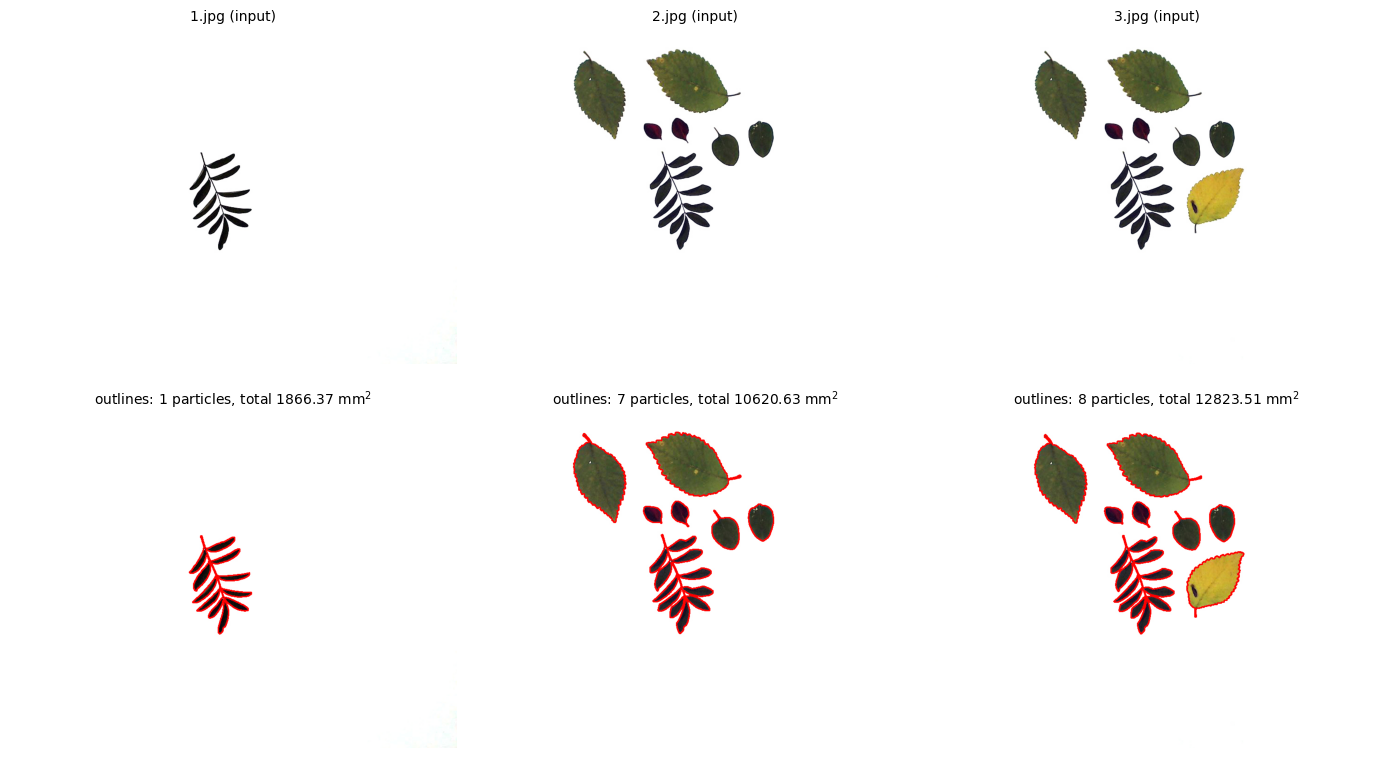

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for j, f in enumerate(SAMPLES):
    name = f.split("/")[-1]
    img = cv2.imread(f)[:, :, ::-1]
    _, mask, parts = analyze_particles(img)
    axes[0, j].imshow(img)
    axes[0, j].set_title(f"{name} (input)", fontsize=10)
    axes[0, j].axis("off")
    vis = img.copy()
    cv2.drawContours(vis, [p["contour"] for p in parts], -1, (255, 0, 0), 2)
    axes[1, j].imshow(vis)
    axes[1, j].set_title(f"outlines: {len(parts)} particles, total {results[name]['total_mm2']} mm$^2$", fontsize=10)
    axes[1, j].axis("off")
plt.tight_layout(); plt.show()

## 9. Adapted resolution-independence check — 解像度依存性の確認（ADAPTED）

**ADAPTED PYTHON DEMONSTRATION.** The paper scans the *same* leaf cardboard at 200–1200 dpi and reports
NRMSE 0.056–0.212% between resolutions (Plant Methods 18:61, Results). Real multi-dpi scans of these camera
samples do not exist, so this cell *simulates* lower capture resolutions by area-downsampling the first
sample and re-running the full pipeline (physical scale preserved). Camera JPEGs behave differently from
scanner TIFFs — the numbers below are a property of this adaptation, **not** a reproduction of the paper's
Fig. 2（実際の複数dpiスキャンはないため、ダウンサンプリングによる模擬比較です。論文のFig.2の再現ではありません）.

  200 dpi: OLA =   3036.62 mm^2 (+62.70% vs 1200)
  300 dpi: OLA =   2599.77 mm^2 (+39.30% vs 1200)
  400 dpi: OLA =   2241.51 mm^2 (+20.10% vs 1200)
  600 dpi: OLA =   2057.27 mm^2 (+10.23% vs 1200)
  800 dpi: OLA =   2030.74 mm^2 (+8.81% vs 1200)
 1000 dpi: OLA =   2007.37 mm^2 (+7.55% vs 1200)
 1200 dpi: OLA =   1866.37 mm^2 (+0.00% vs 1200)
NRMSE vs 1200 dpi: 29.566%  (paper, scanner TIFFs: 0.056-0.212%)


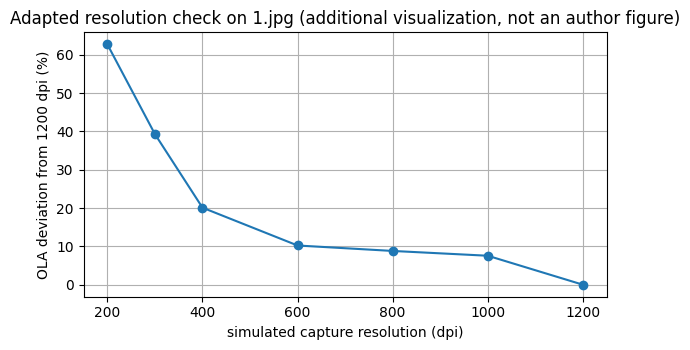

In [ ]:
ref_img = cv2.imread(SAMPLES[0])[:, :, ::-1]
H, W = ref_img.shape[:2]
sim = {}
for dpi in [200, 300, 400, 600, 800, 1000, 1200]:
    s = dpi / 1200.0
    small = cv2.resize(ref_img, (max(1, round(W * s)), max(1, round(H * s))), interpolation=cv2.INTER_AREA)
    _, _, parts = analyze_particles(small)
    mm_per_px = (CALIB_RATIO * H) / small.shape[0]
    sim[dpi] = sum(p["area_px2"] for p in parts) * mm_per_px ** 2
ref = sim[1200]
for dpi, a in sim.items():
    print(f"{dpi:5d} dpi: OLA = {a:9.2f} mm^2 ({100 * (a - ref) / ref:+.2f}% vs 1200)")
nrmse = float(np.sqrt(np.mean([((a - ref) / ref) ** 2 for a in sim.values()])))
print(f"NRMSE vs 1200 dpi: {100 * nrmse:.3f}%  (paper, scanner TIFFs: 0.056-0.212%)")

plt.figure(figsize=(6, 3.6))
plt.plot(list(sim.keys()), [100 * (a - ref) / ref for a in sim.values()], "o-")
plt.xlabel("simulated capture resolution (dpi)"); plt.ylabel("OLA deviation from 1200 dpi (%)")
plt.title("Adapted resolution check on 1.jpg (additional visualization, not an author figure)")
plt.grid(True); plt.tight_layout(); plt.show()

## 10. Export results — 結果のCSV出力

Writes the macro's output file structure under `/content/ola_results/`: one CSV per image plus a
`Total values.csv`（マクロと同じ構成でCSVを出力します）.

In [ ]:
import os
OUT = "/content/ola_results"
os.makedirs(OUT, exist_ok=True)
for name, r in results.items():
    stem = os.path.splitext(name)[0]
    r["df"].to_csv(f"{OUT}/{stem}.csv", index=False)
pd.DataFrame([{"Label": k, "Total area (mm2)": v["total_mm2"]} for k, v in results.items()]).to_csv(
    f"{OUT}/Total values.csv", index=False)
print(sorted(os.listdir(OUT)))

['1.csv', '2.csv', '3.csv', 'Total values.csv']


## Interpretation and validation record — 解釈と検証記録

**What was validated (this run, fresh Colab CPU runtime):** pinned downloads verified by git blob SHA-1;
Huang port cross-checked against ImageJ's second implementation; calibration guard passes (single object,
circularity ≥ 0.85); 3 sample images measured with per-particle tables and totals; CSVs exported.

**Reference values:** the paper's scanner-mode OLA agrees with volumetric leaf area with NRMSE 2.61%
(*Plant Methods* 18:61) and resolution effects of 0.056–0.212% NRMSE. These are dataset-level results of the
full study — a 3-image demonstration does not verify them; it only exercises the authors' measurement tool.

**Known limitations:** (1) perimeter excludes inner-hole boundaries; (2) with the default 0–Infinity size
sieve, shadows/other dark objects in the sample scenes are included in the totals, as the macro would;
(3) the resolution check is an adapted simulation on camera JPEGs, not the paper's scanner experiment;
(4) REFactor is fixed at 1.

**References**
- Haghshenas & Emam 2022, *Plant Methods* 18:61, doi:10.1186/s13007-022-00896-w (PMC9082961) — journal version of the target preprint doi:10.21203/rs.3.rs-1370314/v1.
- OLA.ijm v1.0.0 and README.pdf, haqueshenas/Optical-Leaf-Area @ 36a4e4dc6dece0b0d33d02ae4a78a1c41da61c86, MIT.
- Huang L.-K. & Wang M.-J.J. (1995) *Pattern Recognition* 28(1):41-51; ImageJ `ij/process/AutoThresholder.java` @ a376e43fad41a7337f7f01433c9673ed376b40e6.